<a href="https://colab.research.google.com/github/swatepriya11-netizen/ai-ML-lab./blob/main/Multiple_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

# Load Dataset
df = pd.read_csv("laptop_price.csv")

print(df.head())
print(df.info())



   RAM_GB  SSD_GB  Processor_GHz  Battery_Hours  Price
0       4     128            2.0              5  32000
1       4     256            2.2              6  36000
2       8     256            2.4              7  45000
3       8     512            2.6              8  56000
4      16     512            2.8              9  72000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   RAM_GB         20 non-null     int64  
 1   SSD_GB         20 non-null     int64  
 2   Processor_GHz  20 non-null     float64
 3   Battery_Hours  20 non-null     int64  
 4   Price          20 non-null     int64  
dtypes: float64(1), int64(4)
memory usage: 932.0 bytes
None


In [ ]:
# Independent Variables
X = df[['RAM_GB', 'SSD_GB', 'Processor_GHz', 'Battery_Hours']]



In [ ]:
# Dependent Variable
y = df['Price']



In [ ]:
# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)



In [ ]:
# Train Model
model = LinearRegression()
model.fit(X_train, y_train)



LinearRegression()

In [ ]:
# Prediction
y_pred = model.predict(X_test)



In [ ]:
# Regression Equation
print("\nIntercept:", model.intercept_)
print("\nCoefficients")

for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature}: {coef:.2f}")




Intercept: -71373.8314499777

Coefficients
RAM_GB: 1288.99
SSD_GB: 8.26
Processor_GHz: 33019.46
Battery_Hours: 3346.77


In [ ]:
# Evaluation
print("\nModel Evaluation")
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² :", r2_score(y_test, y_pred))




Model Evaluation
MAE : 6486.862525317076
MSE : 67941481.22501516
RMSE: 8242.66226561632
R² : 0.7460131542990087


In [ ]:
# Predict New Laptop Price
new_laptop = pd.DataFrame({
    "RAM_GB": [16],
    "SSD_GB": [1024],
    "Processor_GHz": [3.2],
    "Battery_Hours": [11]
})

predicted_price = model.predict(new_laptop)

print("\nPredicted Laptop Price:", predicted_price[0])


Predicted Laptop Price: 100188.29078427871


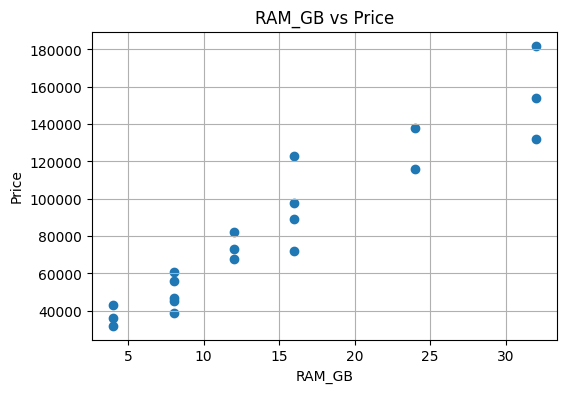

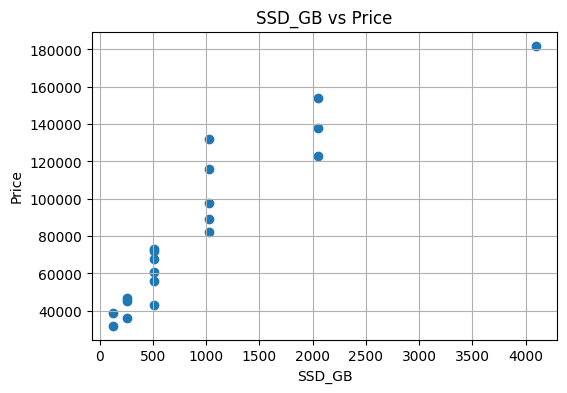

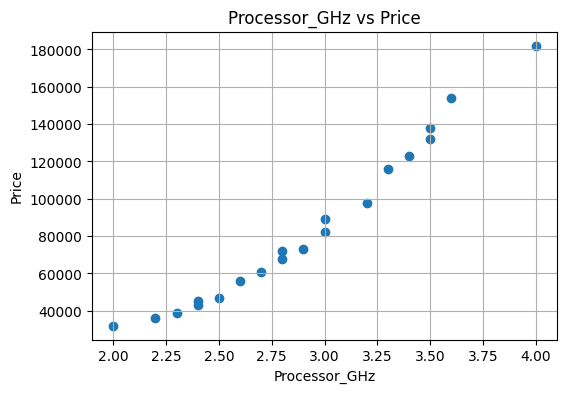

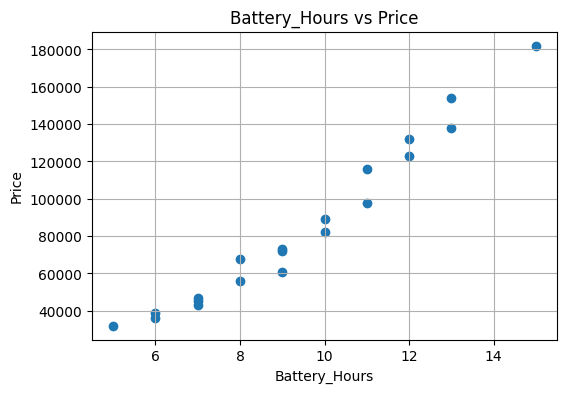

In [ ]:
import matplotlib.pyplot as plt

features = ["RAM_GB", "SSD_GB", "Processor_GHz", "Battery_Hours"]

for feature in features:
    plt.figure(figsize=(6,4))
    plt.scatter(df[feature], df["Price"])
    plt.xlabel(feature)
    plt.ylabel("Price")
    plt.title(f"{feature} vs Price")
    plt.grid(True)
    plt.show()